# Tutorial 11 — Extending chemistry and scoring

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/uw-ipd/tmol/blob/master/docs/tutorial/11_extending_chemistry_and_scoring.ipynb)

What changes when we make one bond harder to stretch? We will build a small peptide and finish with two score curves that isolate a change to proline's N–CD bond spring constant.

**We will:**

1. Follow the chemistry objects and keep only the residue types needed for `AGSPA`.
2. Create a derived database with one doubled spring constant.
3. Move proline CD through eleven positions and compare the original and modified scores.

The original database stays unchanged. This extends [loading](01_working_with_tmol.ipynb) and [scoring](03_scoring_and_analysis.ipynb).


## Setup

In Colab, choose a **GPU runtime** and **Run all**. For local execution, follow the [installation guide](../installation.md) with the documentation extras. Run cells in order; setup selects CUDA when available, otherwise CPU.

We build a short peptide from sequence; no structure download is needed.


In [1]:
try:
    import google.colab  # noqa: F401
except ImportError:
    IN_COLAB = False
else:
    IN_COLAB = True

if IN_COLAB:
    from urllib.request import urlopen

    exec(
        urlopen(
            "https://raw.githubusercontent.com/uw-ipd/tmol/"
            "master/docs/tutorial/colab_setup.py"
        ).read(),
        globals(),
    )
    setup_colab([])


In [2]:
import logging

# The example files do not need local PDB or CCD mirrors.
logging.getLogger("atomworks.constants").addFilter(
    lambda record: not record.getMessage().startswith(
        (
            "Environment variable CCD_MIRROR_PATH not set.",
            "Environment variable PDB_MIRROR_PATH not set.",
        )
    )
)

import copy

import attrs
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display

import tmol
from tmol.chemical import ResidueTypeSet
from tmol.database import ParameterDatabase
from tmol.database.scoring import CartBondedDatabase
from tmol.pose import PackedBlockTypes
from tmol.score import ScoreFunction, ScoreType, beta2016_score_function

SEED = 20260910
np.random.seed(SEED)
torch.manual_seed(SEED)

device = (
    torch.device("cuda", torch.cuda.current_device())
    if tmol.has_cuda() and torch.cuda.is_available()
    else torch.device("cpu")
)


from itables import show as show_table

# Format displayed numbers without changing the values used in calculations.
pd.options.display.float_format = "{:.4g}".format

environment_frame = pd.DataFrame(
    [
        {"component": "TMol", "version": tmol.__version__},
        {"component": "PyTorch", "version": torch.__version__},
        {"component": "device", "version": str(device)},
    ]
)
show_table(environment_frame)


## Follow chemistry from the database to a pose

| Object | Role in this example |
| --- | --- |
| `ParameterDatabase` | Atom definitions and scoring parameters |
| `ResidueTypeSet` | Usable residue types, including terminal variants |
| `PackedBlockTypes` | Those types packed into device tensors |
| `CanonicalOrdering` | Named atoms mapped to external tensor slots |
| `ScoreFunction` | Weights for the score terms |

The diagram shows which objects share this information. A rendered scorer can be reused while only coordinates change; a new layout requires a new scorer.


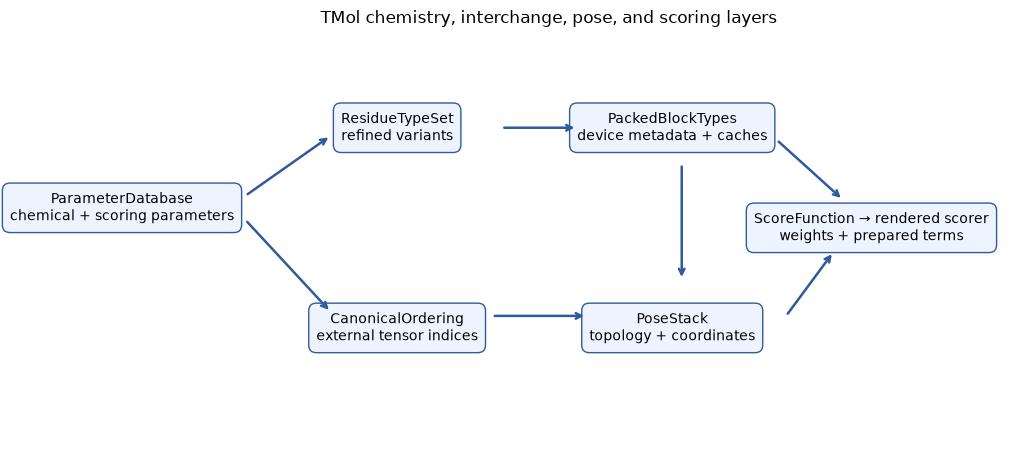

In [3]:
fig, ax = plt.subplots(figsize=(10.5, 4.6))
ax.set_axis_off()
boxes = {
    "ParameterDatabase\nchemical + scoring parameters": (0.05, 0.58),
    "ResidueTypeSet\nrefined variants": (0.34, 0.78),
    "CanonicalOrdering\nexternal tensor indices": (0.34, 0.28),
    "PackedBlockTypes\ndevice metadata + caches": (0.63, 0.78),
    "PoseStack\ntopology + coordinates": (0.63, 0.28),
    "ScoreFunction → rendered scorer\nweights + prepared terms": (0.84, 0.53),
}
for label, (x, y) in boxes.items():
    ax.text(
        x,
        y,
        label,
        transform=ax.transAxes,
        ha="center",
        va="center",
        bbox={"boxstyle": "round,pad=0.55", "fc": "#eef4ff", "ec": "#315a9b"},
    )
arrows = [
    ((0.18, 0.61), (0.27, 0.76)),
    ((0.18, 0.55), (0.27, 0.32)),
    ((0.45, 0.78), (0.53, 0.78)),
    ((0.44, 0.31), (0.54, 0.31)),
    ((0.64, 0.69), (0.64, 0.40)),
    ((0.75, 0.31), (0.80, 0.47)),
    ((0.74, 0.75), (0.81, 0.60)),
]
for start, end in arrows:
    ax.annotate(
        "",
        xy=end,
        xytext=start,
        xycoords="axes fraction",
        arrowprops={"arrowstyle": "->", "lw": 1.8, "color": "#315a9b"},
    )
ax.set_title("TMol chemistry, interchange, pose, and scoring layers", pad=12)
plt.tight_layout()
plt.show()


## Count the available residue types

The database contains base residue definitions and patches such as termini. `ResidueTypeSet.from_database()` combines them into usable types. Grouping by chemical family shows why the result has many more than twenty entries.


In [4]:
parameter_db = ParameterDatabase.get_default()
residue_type_set = ResidueTypeSet.from_database(parameter_db.chemical)


Group the refined types by polymer family and count them.


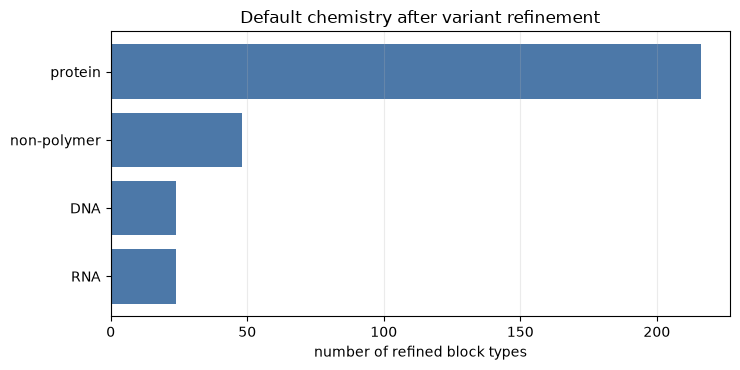

In [5]:
def chemistry_family(residue_type):
    polymer = residue_type.properties.polymer
    if not polymer.is_polymer:
        return "non-polymer"
    if polymer.polymer_type == "amino_acid":
        return "protein"
    if polymer.backbone_type == "dna":
        return "DNA"
    if polymer.backbone_type == "rna":
        return "RNA"
    return polymer.backbone_type or "other polymer"


inventory_frame = pd.DataFrame(
    [
        {
            "block_type": residue_type.name,
            "name3": residue_type.name3,
            "family": chemistry_family(residue_type),
            "atoms": len(residue_type.atoms),
            "torsions": len(residue_type.torsions),
        }
        for residue_type in residue_type_set.residue_types
    ]
)
family_counts = (
    inventory_frame.groupby("family", as_index=False)
    .size()
    .sort_values("size", ascending=False)
    .rename(columns={"size": "refined_block_types"})
)
show_table(family_counts)

fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.barh(
    family_counts["family"][::-1],
    family_counts["refined_block_types"][::-1],
    color="#4c78a8",
)
ax.set(
    xlabel="number of refined block types",
    title="Default chemistry after variant refinement",
)
ax.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.show()


Each entry is a chemical alternative, not a sequence position. For example, an internal alanine and a terminal alanine need different definitions.


## Keep only the types needed for AGSPA

Select ALA, GLY, SER, PRO, and their terminal variants with `create_stable_subset()`. It preserves deterministic ordering and the full scoring database. Build the peptide `AGSPA` to check that the subset covers every position.


In [6]:
subset_db = parameter_db.create_stable_subset(
    desired_names=["ALA", "GLY", "SER", "PRO"],
    desired_variants=["nterm", "cterm"],
)
subset_restype_set = ResidueTypeSet.from_database(subset_db.chemical)
subset_pbt = PackedBlockTypes.from_restype_list(
    subset_db.chemical,
    subset_restype_set,
    subset_restype_set.residue_types,
    device,
)
subset_ordering = tmol.CanonicalOrdering.from_chemdb(subset_db.chemical)
peptide = tmol.extended_pose_stack_from_sequences(
    "AGSPA", device=device, param_db=subset_db
)


Compare database and packed-type counts, then view the peptide.


In [7]:
subset_frame = pd.DataFrame(
    [
        {
            "context": "default refined chemistry",
            "refined_types": len(residue_type_set.residue_types),
            "packed_types": tmol.default_packed_block_types(device).n_types,
            "canonical_equivalence_classes": tmol.default_canonical_ordering().n_restype_io_equiv_classes,
        },
        {
            "context": "AGSP subset",
            "refined_types": len(subset_restype_set.residue_types),
            "packed_types": subset_pbt.n_types,
            "canonical_equivalence_classes": subset_ordering.n_restype_io_equiv_classes,
        },
    ]
)
show_table(subset_frame)
print(
    "pose block types:",
    [peptide.block_type(0, i).name for i in range(peptide.max_n_blocks)],
)

peptide_viewer = tmol.view(peptide, width=720, height=380)
peptide_viewer.show()


pose block types: ['ALA:nterm', 'GLY', 'SER', 'PRO', 'ALA:cterm']


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

The viewer shows a peptide built from ideal internal geometry. Building it confirms type coverage; it does not fold the peptide.


## Isolate the bond-length term

Changing a score weight scales an existing contribution. Changing a database parameter changes how that contribution is calculated.

To measure the effect of one spring constant, enable only `cart_lengths`. Other Cartesian bonded terms may still appear in the rendered output because they share an implementation, but their weights are zero.


In [8]:
beta = beta2016_score_function(device, param_db=subset_db)
focused = ScoreFunction(subset_db, device)
focused.set_weight(ScoreType.cart_lengths, 1.0)


Compare the full beta2016 weights with the one-term score function. Only `cart_lengths` has a nonzero weight in the latter.


In [9]:
weight_rows = []
for score_type in beta.all_score_types():
    weight = float(beta.get_weight(score_type).detach().cpu())
    if weight != 0.0:
        weight_rows.append(
            {"score_type": score_type.name, "beta2016_weight": weight}
        )
weight_frame = pd.DataFrame(weight_rows)
weight_frame["focused_cart_length_weight"] = (
    weight_frame["score_type"].map({"cart_lengths": 1.0}).fillna(0.0)
)
show_table(weight_frame)
focused_nonzero = [
    score_type
    for score_type in focused.all_score_types()
    if float(focused.get_weight(score_type).detach().cpu()) != 0.0
]
print(
    "focused rendered score lanes:",
    [st.name for st in focused.all_score_types()],
)
print("focused nonzero weights:", [st.name for st in focused_nonzero])
assert focused_nonzero == [ScoreType.cart_lengths]


focused rendered score lanes: ['cart_lengths', 'cart_angles', 'cart_torsions', 'cart_impropers', 'cart_hxltorsions']
focused nonzero weights: ['cart_lengths']


## Double the proline N–CD spring constant

Create a derived database with one change: double the spring constant for the bond between proline N and CD. `attrs.evolve()` replaces immutable layers while leaving the original database intact.

Then move only CD by a series of displacements and score each position with both parameter sets. This controlled experiment tests the effect of the edit; it does not fit or validate a new force field.


In [10]:
cart_db = subset_db.scoring.cartbonded
pro_params = cart_db.residue_params["PRO"]
parameter_index, original_n_cd = next(
    (index, parameter)
    for index, parameter in enumerate(pro_params.length_parameters)
    if {parameter.atm1, parameter.atm2} == {"N", "CD"}
)
strengthened_n_cd = attrs.evolve(original_n_cd, K=2.0 * original_n_cd.K)
strengthened_lengths = list(pro_params.length_parameters)
strengthened_lengths[parameter_index] = strengthened_n_cd
strengthened_pro = attrs.evolve(
    pro_params, length_parameters=tuple(strengthened_lengths)
)
strengthened_residue_params = copy.deepcopy(cart_db.residue_params)
strengthened_residue_params["PRO"] = strengthened_pro
strengthened_cart_db = CartBondedDatabase.from_cartres_dict(
    cartres_dict=strengthened_residue_params
)
strengthened_scoring_db = attrs.evolve(
    subset_db.scoring, cartbonded=strengthened_cart_db
)
strengthened_db = attrs.evolve(subset_db, scoring=strengthened_scoring_db)


### Build the two scorers

Both use only the bond-length term. The database’s proline N–CD spring constant is their only parameter difference.


In [11]:
standard_cart = ScoreFunction(subset_db, device)
standard_cart.set_weight(ScoreType.cart_lengths, 1.0)
strengthened_cart = ScoreFunction(strengthened_db, device)
strengthened_cart.set_weight(ScoreType.cart_lengths, 1.0)
standard_scorer = standard_cart.render_whole_pose_scoring_module(peptide)
strengthened_scorer = strengthened_cart.render_whole_pose_scoring_module(
    peptide
)


### Displace proline CD

Move the same atom through eleven positions from 0 to 0.50 Å and score each with both models.


In [12]:
pro_block = next(
    index
    for index in range(peptide.max_n_blocks)
    if peptide.block_type(0, index).name3 == "PRO"
)
pro_type = peptide.block_type(0, pro_block)
pro_offset = int(peptide.block_coord_offset64[0, pro_block])
pro_cd = pro_offset + pro_type.atom_to_idx["CD"]

displacement_values = np.linspace(0.0, 0.50, 11)
scan_rows = []
displaced_coords = None
for displacement in displacement_values:
    coords = peptide.coords.clone()
    coords[0, pro_cd, 0] += float(displacement)
    if displacement == displacement_values[-1]:
        displaced_coords = coords
    scan_rows.append(
        {
            "CD_x_displacement_A": displacement,
            "standard_cart_lengths": float(
                standard_scorer(coords).detach().cpu()[0]
            ),
            "strengthened_cart_lengths": float(
                strengthened_scorer(coords).detach().cpu()[0]
            ),
        }
    )


### Compare relative score curves

Subtract each curve’s value at zero displacement to remove constant offsets.


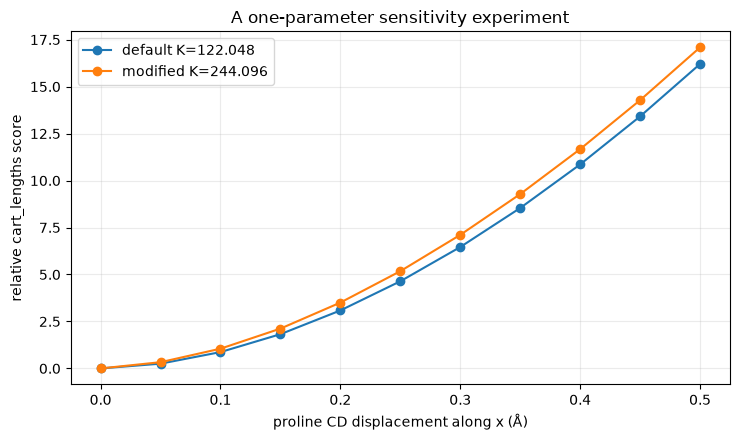

In [13]:
scan_frame = pd.DataFrame(scan_rows)
for column in ["standard_cart_lengths", "strengthened_cart_lengths"]:
    scan_frame[f"relative_{column}"] = (
        scan_frame[column] - scan_frame[column].iloc[0]
    )
show_table(scan_frame.iloc[[0, 2, 5, 10]])

fig, ax = plt.subplots(figsize=(7.5, 4.5))
ax.plot(
    scan_frame["CD_x_displacement_A"],
    scan_frame["relative_standard_cart_lengths"],
    marker="o",
    label=f"default K={original_n_cd.K:g}",
)
ax.plot(
    scan_frame["CD_x_displacement_A"],
    scan_frame["relative_strengthened_cart_lengths"],
    marker="o",
    label=f"modified K={strengthened_n_cd.K:g}",
)
ax.set(
    xlabel="proline CD displacement along x (Å)",
    ylabel="relative cart_lengths score",
    title="A one-parameter sensitivity experiment",
)
ax.grid(alpha=0.25)
ax.legend()
plt.tight_layout()
plt.show()

assert (
    parameter_db.scoring.cartbonded.residue_params["PRO"].length_parameters
    != strengthened_pro.length_parameters
)
assert (
    scan_frame["relative_strengthened_cart_lengths"].iloc[-1]
    > scan_frame["relative_standard_cart_lengths"].iloc[-1]
)


In [14]:
displaced_peptide = attrs.evolve(peptide, coords=displaced_coords)
display(
    tmol.switchable_view(
        {
            "ideal input": peptide,
            "CD displaced by 0.50 Å": displaced_peptide,
        },
        notes={
            "ideal input": "Subset-built AGSPA peptide",
            "CD displaced by 0.50 Å": "Only the internal proline CD coordinate was translated",
        },
        width=720,
        height=380,
    )
)


## Read the parameter experiment

We built `AGSPA` from a restricted database and changed one parameter without editing the original. The difference between the curves isolates the changed parameter. Each absolute curve also includes the other bond-length penalties. Use the viewer to confirm that only CD was displaced.

Before using a custom database in a scientific workflow, test its values and gradients on the relevant devices and record the source of its parameters.

## Try it

1. Add VAL to the subset and build `AGSPV`.
2. Change an angle parameter and design a coordinate perturbation that tests it.
3. Enable gradients during the CD scan and compare the two derivatives.

## References

- [Database API](../api/database.rst)
- [Score API](../api/score.rst)
